# [Student] 🐼 Pandas for Data Analysis: Basics + Customer Churn Project
**Section 1:** learn pandas functions and attributes on small examples (no file needed).  
**Section 2:** a real project on `customer_churn.csv`: clean → explore → visualise → model.

---
## Section 2 preview: the story
### 🎬 The story
You've just joined **KeralaNet Broadband** as a junior data analyst. On day one your manager drops a file on your desk:

> *"We're losing customers every month and nobody knows why. Here's our customer data, `customer_churn.csv`. Find out **who** is leaving, **why** they leave, and build something that can **warn us early**."*

Section 2 of this notebook is your project. Work through Parts A–F. Each ✏️ **Question** has an empty code cell for your answer. 💡 **Business insight** cells ask you to explain what the numbers mean, in plain words, as you would to your manager.

| Part | What you'll do |
|---|---|
| A | Meet the data |
| B | Clean the data |
| C | EDA: answer the manager's questions |
| C2 | Visualising with Matplotlib |
| D | Prepare the data for a model |
| E | Build a logistic regression model |
| F | Recommendations and challenges |

You only need `customer_churn.csv` from **Section 2** onwards. Section 1 needs no files.

## Setup (run this cell)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (8, 4)

---
# 📘 SECTION 1: Pandas Basics
Before the project, let's learn the main **functions, attributes and methods** of pandas on small tables we type in ourselves. **No CSV is needed for this section.**

> **Attribute** is a fact about an object; there are no brackets: `df.shape`, `s.size`
> **Method** is an action; it needs brackets: `df.head()`, `s.mean()`
> **Function** is called from `pd`: `pd.Series()`, `pd.DataFrame()`, `pd.read_csv()`

## 1.1 Series: a single column of data

In [2]:
prices = pd.Series([120, 40, 90, 50], index=["Mango", "Banana", "Jackfruit", "Papaya"])
prices

Mango        120
Banana        40
Jackfruit     90
Papaya        50
dtype: int64

In [3]:
# Attributes (no brackets)
print("size     :", prices.size)
print("dtype    :", prices.dtype)
print("index    :", list(prices.index))
print("values   :", prices.values)
print("is_unique:", prices.is_unique)

size     : 4
dtype    : int64
index    : ['Mango', 'Banana', 'Jackfruit', 'Papaya']
values   : [120  40  90  50]
is_unique: True


In [4]:
# Methods (with brackets)
print("sum :", prices.sum())
print("mean:", prices.mean())
print("max :", prices.max(), "| idxmax:", prices.idxmax())
prices.sort_values(ascending=False)

sum : 300
mean: 75.0
max : 120 | idxmax: Mango


Mango        120
Jackfruit     90
Papaya        50
Banana        40
dtype: int64

### ✏️ Question 1.1a
Create a Series `marks` from a **dictionary**: `{'Anu': 78, 'Ben': 92, 'Chitra': 65, 'Dev': 88, 'Esha': 92}`. Print its `size`, `mean()`, `median()`, `mode()` and `is_unique`.

In [5]:
# YOUR CODE HERE
marks = pd.Series({
    'Anu': 78,
    'Ben': 92,
    'Chitra': 65,
    'Dev': 88,
    'Esha': 92
})

print("Series:")
print(marks)

print(marks.size)
print(marks.mean())
print(marks.median())
print(marks.mode())
print(marks.is_unique)

Series:
Anu       78
Ben       92
Chitra    65
Dev       88
Esha      92
dtype: int64
5
83.0
88.0
0    92
dtype: int64
False


### ✏️ Question 1.1b
Who scored the highest and the lowest in `marks`? Sort the marks from highest to lowest.

In [6]:
# YOUR CODE HERE
print(marks[marks == marks.max()])

print(marks[marks == marks.min()])

print(marks.sort_values(ascending=False))

Ben     92
Esha    92
dtype: int64
Chitra    65
dtype: int64
Ben       92
Esha      92
Dev       88
Anu       78
Chitra    65
dtype: int64


## 1.2 Selecting values: `iloc`, `loc`, `get`
- `iloc[...]` selects by **position** (0, 1, 2…)
- `loc[...]` selects by **label**
- `get(label, default)` selects by label without raising an error if the label is missing

In [7]:
print(prices.iloc[0])            # first value
print(prices.loc["Banana"])       # by label
print(prices.iloc[1:3])           # positions 1 and 2
print(prices.get("Apple", "Not found"))

120
40
Banana       40
Jackfruit    90
dtype: int64
Not found


### ✏️ Question 1.2a
From `marks`, get (a) the 3rd value by position, (b) Dev's mark by label, (c) the last two values, (d) `'Farah'` with a default of `0`.

In [8]:
# YOUR CODE HERE
print(marks.iloc[2])

print(marks['Dev'])

print(marks.tail(2))

print(marks.get('Farah', 0))

65
88
Dev     88
Esha    92
dtype: int64
0


## 1.3 Broadcasting, `value_counts`, `apply`, `map`

In [9]:
print(prices * 1.18)          # one operation applied to every value (add 18% GST)

colours = pd.Series(["Red", "Blue", "Red", "Green", "Red", "Blue"])
print(colours.value_counts())
print(colours.value_counts(normalize=True))   # proportions

Mango        141.6
Banana        47.2
Jackfruit    106.2
Papaya        59.0
dtype: float64
Red      3
Blue     2
Green    1
Name: count, dtype: int64
Red      0.500000
Blue     0.333333
Green    0.166667
Name: proportion, dtype: float64


In [10]:
def grade(m):
    return "A" if m >= 90 else "B" if m >= 75 else "C"

print(marks.apply(grade))                                # apply runs a function on every value
print(colours.map({"Red": "R", "Blue": "B", "Green": "G"}))   # map swaps values using a dict

Anu       B
Ben       A
Chitra    C
Dev       B
Esha      A
dtype: object
0    R
1    B
2    R
3    G
4    R
5    B
dtype: object


### ✏️ Question 1.3a
Give every student in `marks` 5 grace marks, then use `apply(grade)` to find each student's grade. How many students got each grade?

In [11]:
# YOUR CODE HERE
marks = marks + 5

grades = marks.apply(grade)

print(marks)

print(grades)

print(grades.value_counts())


Anu       83
Ben       97
Chitra    70
Dev       93
Esha      97
dtype: int64
Anu       B
Ben       A
Chitra    C
Dev       A
Esha      A
dtype: object
A    3
B    1
C    1
Name: count, dtype: int64


## 1.4 DataFrames: a table of Series

In [12]:
emp = pd.DataFrame({
    "Name":   ["Asha", "Ravi", "Meera", "John", "Fathima", "Kiran", "Ravi"],
    "Dept":   ["IT", "HR", "IT", "Sales", "HR", "Sales", "HR"],
    "Age":    [28, 35, None, 42, 30, 25, 35],
    "Salary": [55000, 48000, 62000, 70000, None, 39000, 48000],
    "City":   [" kochi", "Thrissur", "KOCHI ", "Kollam", "thrissur", "Kochi", "Thrissur"],
    "Joined": ["2021-03-15", "2018-07-01", "2020-01-10", "2015-11-20", "2022-05-05", "2023-02-01", "2018-07-01"],
})
emp

,Name,Dept,Age,Salary,City,Joined
0,Asha,IT,28.0,55000.0,kochi,2021-03-15
1,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01
2,Meera,IT,NaN,62000.0,KOCHI,2020-01-10
3,John,Sales,42.0,70000.0,Kollam,2015-11-20
4,Fathima,HR,30.0,NaN,thrissur,2022-05-05
5,Kiran,Sales,25.0,39000.0,Kochi,2023-02-01
6,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01


In [13]:
# Attributes
print("shape  :", emp.shape)
print("columns:", list(emp.columns))
print("index  :", emp.index)
print(emp.dtypes)

shape  : (7, 6)
columns: ['Name', 'Dept', 'Age', 'Salary', 'City', 'Joined']
index  : RangeIndex(start=0, stop=7, step=1)
Name       object
Dept       object
Age       float64
Salary    float64
City       object
Joined     object
dtype: object


In [14]:
emp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Name    7 non-null      object 
 1   Dept    7 non-null      object 
 2   Age     6 non-null      float64
 3   Salary  6 non-null      float64
 4   City    7 non-null      object 
 5   Joined  7 non-null      object 
dtypes: float64(2), object(4)
memory usage: 464.0+ bytes


In [15]:
emp.describe()

,Age,Salary
count,6.000000,6.000000
mean,32.500000,53666.666667
std,6.090977,11111.555547
min,25.000000,39000.000000
25%,28.500000,48000.000000
50%,32.500000,51500.000000
75%,35.000000,60250.000000
max,42.000000,70000.000000


### ✏️ Question 1.4a
Show the first 3 rows and the last 2 rows of `emp`. How many rows and columns does it have?

In [16]:
# YOUR CODE HERE
print(emp.head(3))

print(emp.tail(2))

emp.shape

    Name Dept   Age   Salary      City      Joined
0   Asha   IT  28.0  55000.0     kochi  2021-03-15
1   Ravi   HR  35.0  48000.0  Thrissur  2018-07-01
2  Meera   IT   NaN  62000.0    KOCHI   2020-01-10
    Name   Dept   Age   Salary      City      Joined
5  Kiran  Sales  25.0  39000.0     Kochi  2023-02-01
6   Ravi     HR  35.0  48000.0  Thrissur  2018-07-01


(7, 6)

## 1.5 Working with columns

In [17]:
print(type(emp["Name"]))          # one column gives a Series
emp[["Name", "Salary"]]           # a list of columns gives a DataFrame

<class 'pandas.core.series.Series'>


,Name,Salary
0,Asha,55000.0
1,Ravi,48000.0
2,Meera,62000.0
3,John,70000.0
4,Fathima,NaN
5,Kiran,39000.0
6,Ravi,48000.0


In [18]:
emp["Bonus"] = emp["Salary"] * 0.10                     # add a column
emp = emp.rename(columns={"Dept": "Department"})        # rename a column
emp.head(3)

,Name,Department,Age,Salary,City,Joined,Bonus
0,Asha,IT,28.0,55000.0,kochi,2021-03-15,5500.0
1,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01,4800.0
2,Meera,IT,NaN,62000.0,KOCHI,2020-01-10,6200.0


In [19]:
emp = emp.drop(columns="Bonus")                         # drop a column
emp["Department"] = emp["Department"].astype("category") # change the dtype
emp.dtypes

Name            object
Department    category
Age            float64
Salary         float64
City            object
Joined          object
dtype: object

### ✏️ Question 1.5a
Add a column `Salary_Lakhs` = `Salary / 100000`, rounded to 2 decimals. Show only `Name` and `Salary_Lakhs`.

In [20]:
# YOUR CODE HERE
emp["Salary_Lakhs"] = (emp["Salary"] / 100000).round(2)

emp[["Name", "Salary_Lakhs"]]


,Name,Salary_Lakhs
0,Asha,0.55
1,Ravi,0.48
2,Meera,0.62
3,John,0.70
4,Fathima,NaN
5,Kiran,0.39
6,Ravi,0.48


## 1.6 Filtering rows
A filter is a **True/False Series** placed inside `df[...]`. Combine filters with `&` (AND), `|` (OR) and `~` (NOT), and always put brackets around each condition.

In [21]:
emp[emp["Age"] > 30]

,Name,Department,Age,Salary,City,Joined,Salary_Lakhs
1,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01,0.48
3,John,Sales,42.0,70000.0,Kollam,2015-11-20,0.70
6,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01,0.48


In [22]:
emp[(emp["Department"] == "HR") & (emp["Salary"] > 45000)]

,Name,Department,Age,Salary,City,Joined,Salary_Lakhs
1,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01,0.48
6,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01,0.48


In [23]:
print(emp[emp["Department"].isin(["IT", "Sales"])]["Name"].tolist())
print(emp[emp["Age"].between(25, 32)]["Name"].tolist())
emp[emp["Salary"].isnull()]

['Asha', 'Meera', 'John', 'Kiran']
['Asha', 'Fathima', 'Kiran']


,Name,Department,Age,Salary,City,Joined,Salary_Lakhs
4,Fathima,HR,30.0,NaN,thrissur,2022-05-05,NaN


### ✏️ Question 1.6a
Find the employees who work in **IT or Sales** and earn **more than 50,000**.

In [24]:
# YOUR CODE HERE
emp[((emp["Department"] == "IT") | (emp["Department"] == "Sales")) &
    (emp["Salary"] > 50000)]

,Name,Department,Age,Salary,City,Joined,Salary_Lakhs
0,Asha,IT,28.0,55000.0,kochi,2021-03-15,0.55
2,Meera,IT,NaN,62000.0,KOCHI,2020-01-10,0.62
3,John,Sales,42.0,70000.0,Kollam,2015-11-20,0.70


## 1.7 Missing values and duplicates

In [25]:
print(emp.isnull().sum())
print("Duplicate rows:", emp.duplicated().sum())

Name            0
Department      0
Age             1
Salary          1
City            0
Joined          0
Salary_Lakhs    1
dtype: int64
Duplicate rows: 1


In [26]:
clean = emp.drop_duplicates().copy()
clean["Age"] = clean["Age"].fillna(clean["Age"].median())
clean["Salary"] = clean["Salary"].fillna(clean["Salary"].mean())
print(clean.isnull().sum().sum(), "missing values left")
clean

1 missing values left


,Name,Department,Age,Salary,City,Joined,Salary_Lakhs
0,Asha,IT,28.0,55000.0,kochi,2021-03-15,0.55
1,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01,0.48
2,Meera,IT,30.0,62000.0,KOCHI,2020-01-10,0.62
3,John,Sales,42.0,70000.0,Kollam,2015-11-20,0.70
4,Fathima,HR,30.0,54800.0,thrissur,2022-05-05,NaN
5,Kiran,Sales,25.0,39000.0,Kochi,2023-02-01,0.39


### ✏️ Question 1.7a
Starting from `emp` again, use `dropna()` to drop every row that has **any** missing value. How many rows are left? Why might this be a bad idea in real data?

In [27]:
# YOUR CODE HERE
emp_clean = emp.dropna()
print(emp_clean)
emp_clean.shape


    Name Department   Age   Salary      City      Joined  Salary_Lakhs
0   Asha         IT  28.0  55000.0     kochi  2021-03-15          0.55
1   Ravi         HR  35.0  48000.0  Thrissur  2018-07-01          0.48
3   John      Sales  42.0  70000.0    Kollam  2015-11-20          0.70
5  Kiran      Sales  25.0  39000.0     Kochi  2023-02-01          0.39
6   Ravi         HR  35.0  48000.0  Thrissur  2018-07-01          0.48


(5, 7)

## 1.8 Text (`.str`) and dates (`.dt`)

In [28]:
clean["City"]

0       kochi
1    Thrissur
2      KOCHI 
3      Kollam
4    thrissur
5       Kochi
Name: City, dtype: object

In [29]:
# Step 0: see the hidden spaces
# repr() shows each value in quotes, so leading/trailing spaces become visible
for city in clean["City"]:
    print(repr(city), "-> length:", len(city))

' kochi' -> length: 6
'Thrissur' -> length: 8
'KOCHI ' -> length: 6
'Kollam' -> length: 6
'thrissur' -> length: 8
'Kochi' -> length: 5


In [30]:
# Step 1: .str gives access to string methods for every value in the column
# .str.len() counts the characters in each value (spaces count too)
clean["City"].str.len()

0    6
1    8
2    6
3    6
4    8
5    5
Name: City, dtype: int64

In [31]:
# Step 2: .str.strip() removes spaces from both ends of each value
# Compare the lengths: " kochi" (6) becomes "kochi" (5)
stripped = clean["City"].str.strip()
print(stripped.tolist())
print(stripped.str.len().tolist())

['kochi', 'Thrissur', 'KOCHI', 'Kollam', 'thrissur', 'Kochi']
[5, 8, 5, 6, 8, 5]


In [32]:
# Step 2b: lstrip() removes spaces on the left only, rstrip() on the right only
print(clean["City"].str.lstrip().tolist())
print(clean["City"].str.rstrip().tolist())

['kochi', 'Thrissur', 'KOCHI ', 'Kollam', 'thrissur', 'Kochi']
[' kochi', 'Thrissur', 'KOCHI', 'Kollam', 'thrissur', 'Kochi']


In [33]:
# Step 3: change the letter case
print(stripped.str.lower().tolist())   # all small letters
print(stripped.str.upper().tolist())   # all capital letters
print(stripped.str.title().tolist())   # First Letter Capital

['kochi', 'thrissur', 'kochi', 'kollam', 'thrissur', 'kochi']
['KOCHI', 'THRISSUR', 'KOCHI', 'KOLLAM', 'THRISSUR', 'KOCHI']
['Kochi', 'Thrissur', 'Kochi', 'Kollam', 'Thrissur', 'Kochi']


In [34]:
clean["City"].str.strip()

0       kochi
1    Thrissur
2       KOCHI
3      Kollam
4    thrissur
5       Kochi
Name: City, dtype: object

In [35]:
clean["City"].str.strip().str.title()

0       Kochi
1    Thrissur
2       Kochi
3      Kollam
4    Thrissur
5       Kochi
Name: City, dtype: object

In [36]:
clean["City"].value_counts()

City
 kochi      1
Thrissur    1
KOCHI       1
Kollam      1
thrissur    1
Kochi       1
Name: count, dtype: int64

In [37]:
clean["City"] = clean["City"].str.strip().str.title()
print(clean["City"].value_counts())

City
Kochi       3
Thrissur    2
Kollam      1
Name: count, dtype: int64


In [38]:
print(clean[clean["Name"].str.contains("a")]["Name"].tolist())   # names containing 'a'
print(clean["Name"].str.upper().tolist())

['Asha', 'Ravi', 'Meera', 'Fathima', 'Kiran']
['ASHA', 'RAVI', 'MEERA', 'JOHN', 'FATHIMA', 'KIRAN']


In [39]:
clean["City"] = clean["City"].str.strip().str.title()
print(clean["City"].value_counts())
print(clean[clean["Name"].str.contains("a")]["Name"].tolist())   # names containing 'a'
print(clean["Name"].str.upper().tolist())

City
Kochi       3
Thrissur    2
Kollam      1
Name: count, dtype: int64
['Asha', 'Ravi', 'Meera', 'Fathima', 'Kiran']
['ASHA', 'RAVI', 'MEERA', 'JOHN', 'FATHIMA', 'KIRAN']


In [40]:
clean["Joined"]

0    2021-03-15
1    2018-07-01
2    2020-01-10
3    2015-11-20
4    2022-05-05
5    2023-02-01
Name: Joined, dtype: object

In [41]:
clean["Joined"] = pd.to_datetime(clean["Joined"])
clean["Joined"]

0   2021-03-15
1   2018-07-01
2   2020-01-10
3   2015-11-20
4   2022-05-05
5   2023-02-01
Name: Joined, dtype: datetime64[ns]

In [42]:
clean["JoinYear"] = clean["Joined"].dt.year
clean["JoinYear"]

0    2021
1    2018
2    2020
3    2015
4    2022
5    2023
Name: JoinYear, dtype: int32

In [43]:
clean["JoinDay"] = clean["Joined"].dt.day_name()
clean[["Name", "Joined", "JoinYear", "JoinDay"]]

,Name,Joined,JoinYear,JoinDay
0,Asha,2021-03-15,2021,Monday
1,Ravi,2018-07-01,2018,Sunday
2,Meera,2020-01-10,2020,Friday
3,John,2015-11-20,2015,Friday
4,Fathima,2022-05-05,2022,Thursday
5,Kiran,2023-02-01,2023,Wednesday


In [44]:
clean["Joined"] = pd.to_datetime(clean["Joined"])
clean["JoinYear"] = clean["Joined"].dt.year
clean["JoinDay"] = clean["Joined"].dt.day_name()
clean[["Name", "Joined", "JoinYear", "JoinDay"]]

,Name,Joined,JoinYear,JoinDay
0,Asha,2021-03-15,2021,Monday
1,Ravi,2018-07-01,2018,Sunday
2,Meera,2020-01-10,2020,Friday
3,John,2015-11-20,2015,Friday
4,Fathima,2022-05-05,2022,Thursday
5,Kiran,2023-02-01,2023,Wednesday


### ✏️ Question 1.8a
Which employees joined **before 2020**? Show their names and joining years.

In [45]:
# Employees who joined before 2020
clean.loc[clean["JoinYear"] < 2020, ["Name", "JoinYear"]]

,Name,JoinYear
1,Ravi,2018
3,John,2015


## 1.9 Grouping and sorting

**Why `observed=True`?** It only matters when the group-by column has the `category` dtype (we converted `Department` earlier).
- `observed=True` shows only the categories that actually **appear** in the data.
- `observed=False` shows **every** category, including empty ones, with NaN.
- Writing it explicitly avoids a FutureWarning in pandas 2.x and gives the same result in pandas 3.x.

In [46]:
clean.groupby("Department",observed=True)["Salary"].mean().round(0)

Department
HR       51400.0
IT       58500.0
Sales    54500.0
Name: Salary, dtype: float64

In [47]:
clean.groupby("Department", observed=True).agg(
    people=("Name", "count"),
    avg_salary=("Salary", "mean"),
    oldest=("Age", "max"),
).round(0)

,people,avg_salary,oldest
Department,,,
HR,2,51400.0,35.0
IT,2,58500.0,30.0
Sales,2,54500.0,42.0


In [48]:
print(clean.sort_values("Salary", ascending=False)[["Name", "Salary"]])
clean.nlargest(2, "Salary")[["Name", "Salary"]]

      Name   Salary
3     John  70000.0
2    Meera  62000.0
0     Asha  55000.0
4  Fathima  54800.0
1     Ravi  48000.0
5    Kiran  39000.0


,Name,Salary
3,John,70000.0
2,Meera,62000.0


### ✏️ Question 1.9a
Find the **average age per city**, sorted from highest to lowest.

In [49]:
# YOUR CODE HERE
clean.groupby("City", observed=True)["Age"].mean().sort_values(ascending=False)

City
Kollam      42.000000
Thrissur    32.500000
Kochi       27.666667
Name: Age, dtype: float64

## 1.10 Loops over columns
`df.dtypes` holds every column's data type (the same information `info()` prints), so we can loop over it.

In [50]:
for col, dtype in clean.dtypes.items():
    print(f"--- {col} ({dtype}) ---")
    if dtype == "int64" or dtype == "float64":
        print(clean[col].describe().round(1))
    else:
        print(clean[col].value_counts().head(3))

--- Name (object) ---
Name
Asha     1
Ravi     1
Meera    1
Name: count, dtype: int64
--- Department (category) ---
Department
HR       2
IT       2
Sales    2
Name: count, dtype: int64
--- Age (float64) ---
count     6.0
mean     31.7
std       6.0
min      25.0
25%      28.5
50%      30.0
75%      33.8
max      42.0
Name: Age, dtype: float64
--- Salary (float64) ---
count        6.0
mean     54800.0
std      10759.2
min      39000.0
25%      49700.0
50%      54900.0
75%      60250.0
max      70000.0
Name: Salary, dtype: float64
--- City (object) ---
City
Kochi       3
Thrissur    2
Kollam      1
Name: count, dtype: int64
--- Joined (datetime64[ns]) ---
Joined
2021-03-15    1
2018-07-01    1
2020-01-10    1
Name: count, dtype: int64
--- Salary_Lakhs (float64) ---
count    5.0
mean     0.5
std      0.1
min      0.4
25%      0.5
50%      0.6
75%      0.6
max      0.7
Name: Salary_Lakhs, dtype: float64
--- JoinYear (int32) ---
JoinYear
2021    1
2018    1
2020    1
Name: count, dtype: in

### ✏️ Question 1.10a
Use `select_dtypes` to list the **numeric** columns and the **non-numeric** columns of `clean`.

In [51]:
# YOUR CODE HERE
num = clean.select_dtypes(include="number").columns
other = clean.select_dtypes(exclude="number").columns
print(list(num))
print(list(other))

['Age', 'Salary', 'Salary_Lakhs', 'JoinYear']
['Name', 'Department', 'City', 'Joined', 'JoinDay']


In [52]:
numeric_cols = clean.select_dtypes(include="number").columns
other_cols   = clean.select_dtypes(exclude="number").columns

for col in numeric_cols:
    print(f"--- {col} ---")
    print(clean[col].describe().round(1))

for col in other_cols:
    print(f"--- {col} ---")
    print(clean[col].value_counts().head(3))

--- Age ---
count     6.0
mean     31.7
std       6.0
min      25.0
25%      28.5
50%      30.0
75%      33.8
max      42.0
Name: Age, dtype: float64
--- Salary ---
count        6.0
mean     54800.0
std      10759.2
min      39000.0
25%      49700.0
50%      54900.0
75%      60250.0
max      70000.0
Name: Salary, dtype: float64
--- Salary_Lakhs ---
count    5.0
mean     0.5
std      0.1
min      0.4
25%      0.5
50%      0.6
75%      0.6
max      0.7
Name: Salary_Lakhs, dtype: float64
--- JoinYear ---
count       6.0
mean     2019.8
std         2.9
min      2015.0
25%      2018.5
50%      2020.5
75%      2021.8
max      2023.0
Name: JoinYear, dtype: float64
--- Name ---
Name
Asha     1
Ravi     1
Meera    1
Name: count, dtype: int64
--- Department ---
Department
HR       2
IT       2
Sales    2
Name: count, dtype: int64
--- City ---
City
Kochi       3
Thrissur    2
Kollam      1
Name: count, dtype: int64
--- Joined ---
Joined
2021-03-15    1
2018-07-01    1
2020-01-10    1
Name: count,

## 1.11 Matplotlib basics

C:\Users\ABHIJITH\AppData\Local\Temp\ipykernel_23480\1941027335.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg = clean.groupby("Department")["Salary"].mean()


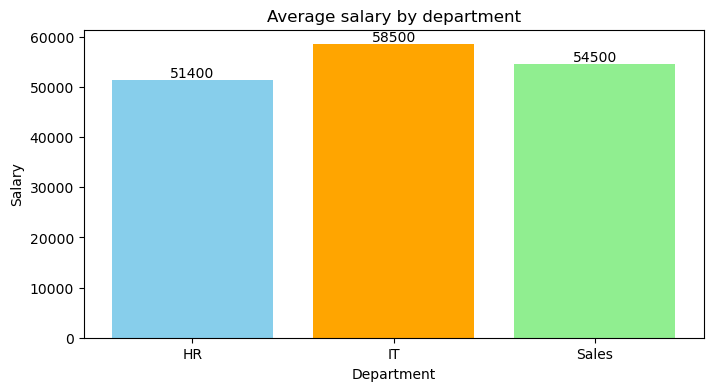

In [53]:
avg = clean.groupby("Department")["Salary"].mean()

bars = plt.bar(avg.index, avg.values, color=["skyblue", "orange", "lightgreen"])
plt.bar_label(bars, fmt="%.0f")      # writes each bar's value on top

plt.title("Average salary by department")
plt.xlabel("Department")
plt.ylabel("Salary")
plt.show()

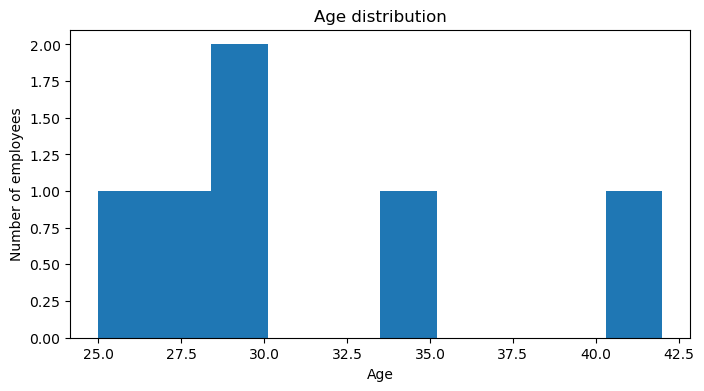

In [54]:
# Histogram: shows how values are spread out
# The x-axis is divided into groups (bins); each bar's height is how many people fall in that group
plt.hist(clean["Age"])
plt.title("Age distribution")
plt.xlabel("Age")
plt.ylabel("Number of employees")
plt.show()

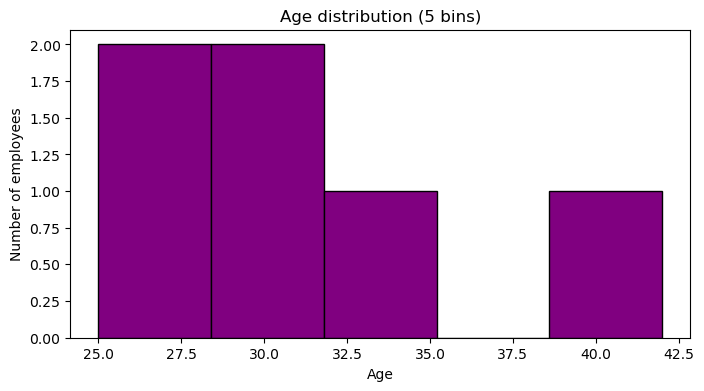

In [55]:
# bins = how many groups to divide the data into
# color = bar colour, edgecolor = outline around each bar
plt.hist(clean["Age"], bins=5, color="purple", edgecolor="black")
plt.title("Age distribution (5 bins)")
plt.xlabel("Age")
plt.ylabel("Number of employees")
plt.show()

**Why do the two histograms look different?** The first used matplotlib's default of **10 bins** (each 1.7 years wide); the second used **5 bins** (each 3.4 years wide). With wider bins, ages 25 and 28 fall into the same group.
The number of bins changes the **shape** of a histogram: too many and it looks spiky, too few and it hides detail. Run the cell below to see the exact bin edges and counts.

Bin edges: [25.  28.4 31.8 35.2 38.6 42. ]
Counts   : [2. 2. 1. 0. 1.]


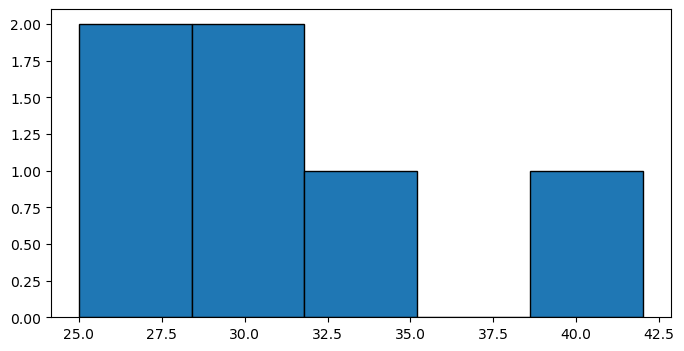

In [56]:
counts, edges, _ = plt.hist(clean["Age"], bins=5, edgecolor="black")
print("Bin edges:", edges.round(1))
print("Counts   :", counts)
plt.show()

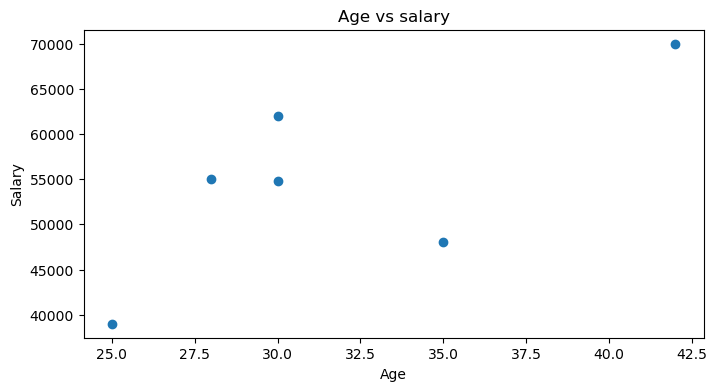

In [57]:
# Scatter plot: shows the relationship between two number columns
# Each dot is one employee: x = Age, y = Salary
plt.scatter(clean["Age"], clean["Salary"])
plt.title("Age vs salary")
plt.xlabel("Age")
plt.ylabel("Salary")
plt.show()

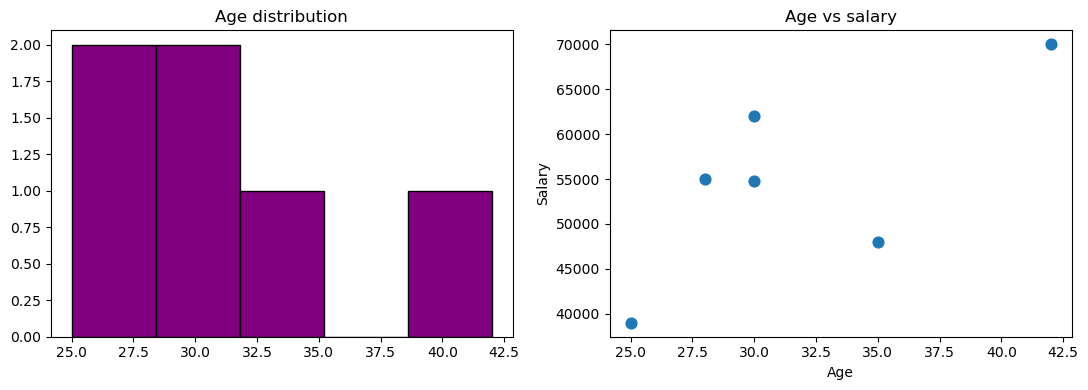

In [58]:
# Two charts side by side with plt.subplots
# subplots(1, 2) = 1 row, 2 columns. ax1 is the left chart, ax2 the right chart
# With ax we use set_title / set_xlabel instead of plt.title / plt.xlabel
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.hist(clean["Age"], bins=5, color="purple", edgecolor="black")
ax1.set_title("Age distribution")

ax2.scatter(clean["Age"], clean["Salary"], s=60)
ax2.set_title("Age vs salary")
ax2.set_xlabel("Age")
ax2.set_ylabel("Salary")

plt.tight_layout()   # stops the charts from overlapping
plt.show()

### ✏️ Question 1.11a
Draw a **horizontal bar chart** (`plt.barh`) of each employee's salary in `clean`, sorted from lowest to highest, with a title.

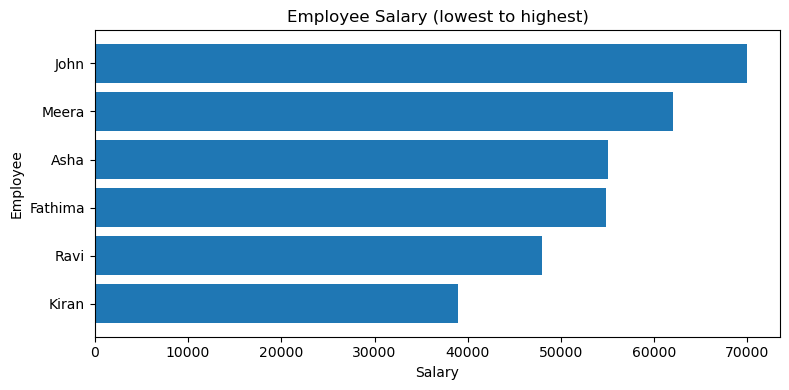

In [59]:
# YOUR CODE HERE
plot_data = clean.sort_values("Salary")
plt.barh(plot_data["Name"], plot_data["Salary"])
plt.title("Employee Salary (lowest to highest)")
plt.xlabel("Salary")
plt.ylabel("Employee")
plt.tight_layout()
plt.show()

## 🧾 Recap: Attributes vs Methods vs Functions
| Attributes (no `()`) | Methods (`()`) | Functions (`pd.`) |
|---|---|---|
| `shape`, `size`, `columns`, `index`, `dtypes`, `values`, `is_unique` | `head`, `tail`, `info`, `describe`, `sum`, `mean`, `sort_values`, `value_counts`, `isnull`, `fillna`, `dropna`, `drop_duplicates`, `groupby`, `apply`, `map`, `rename`, `drop`, `astype` | `pd.Series`, `pd.DataFrame`, `pd.read_csv`, `pd.to_datetime`, `pd.concat`, `pd.get_dummies` |
| `.str` and `.dt` (accessors) | `.str.strip()`, `.str.title()`, `.dt.year`… | |

✅ **You're ready for the real project.**

---
# 📗 SECTION 2: The Churn Project
### ⬇️ Before you start
Download **`customer_churn.csv`** (shared by your instructor) and put it in the **same folder** as this notebook. Then continue below.

---
## Part A: Meet the Data 👋

### ✏️ Question A1
Load `customer_churn.csv` into a DataFrame called `df` and show the first 5 rows.

In [60]:
# YOUR CODE HERE
df = pd.read_csv("customer_churn.csv")
df.head()

,CustomerID,Name,Gender,Age,City,SignupDate,Plan,Contract,MonthlyCharges,TenureMonths,TotalCharges,SupportCalls,PaymentMethod,SeniorCitizen,SatisfactionScore,Churn
0,CUST1113,"Menon, Hari",Male,66.0,Bengaluru,09/07/2025,Standard,One year,521.61,13,6780.93,0,Debit Card,True,2.0,1
1,CUST1795,"Menon, Suresh",Male,18.0,KOLLAM,08/21/2026,Standard,One year,503.05,2,1006.10,2,Net Banking,False,1.0,1
2,CUST1817,"Menon, Arjun",NaN,74.0,Bengaluru,03/11/2023,Standard,One year,538.37,44,23688.28,3,UPI,True,4.0,0
3,CUST1510,"iyer, pooja",Female,66.0,Thiruvananthapuram,10/11/2025,Standard,Month-to-month,494.45,12,5933.40,2,Credit Card,True,NaN,0
4,CUST1492,"Krishnan, Gayathri",NaN,38.0,Kochi,05/19/2025,Standard,Month-to-month,520.10,17,8841.70,0,UPI,False,1.0,0


### ✏️ Question A2
How many rows and columns does the data have?

In [61]:
# YOUR CODE HERE
df.shape

(1012, 16)

### ✏️ Question A3
Use `info()` to see the data types and non-null counts. Which columns have missing values?

In [67]:
# YOUR CODE HERE
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1012 entries, 0 to 1011
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         1012 non-null   object 
 1   Name               1012 non-null   object 
 2   Gender             962 non-null    object 
 3   Age                971 non-null    float64
 4   City               982 non-null    object 
 5   SignupDate         1012 non-null   object 
 6   Plan               1012 non-null   object 
 7   Contract           1012 non-null   object 
 8   MonthlyCharges     1012 non-null   float64
 9   TenureMonths       1012 non-null   int64  
 10  TotalCharges       1012 non-null   float64
 11  SupportCalls       1012 non-null   int64  
 12  PaymentMethod      992 non-null    object 
 13  SeniorCitizen      971 non-null    object 
 14  SatisfactionScore  952 non-null    float64
 15  Churn              1012 non-null   int64  
dtypes: float64(4), int64(3),

CustomerID            0
Name                  0
Gender               50
Age                  41
City                 30
SignupDate            0
Plan                  0
Contract              0
MonthlyCharges        0
TenureMonths          0
TotalCharges          0
SupportCalls          0
PaymentMethod        20
SeniorCitizen        41
SatisfactionScore    60
Churn                 0
dtype: int64

### ✏️ Question A4
Write a **for loop** over `df.dtypes`: for `object` columns print `value_counts()` (top 5), for numeric columns print `describe()`.

In [69]:
# YOUR CODE HERE
for col, dtype in df.dtypes.items():
    if dtype == "object":
        print(df[col].value_counts().head(5))
    else:
        print(df[col].describe())

CustomerID
CUST1507    2
CUST1818    2
CUST1049    2
CUST1142    2
CUST1242    2
Name: count, dtype: int64
Name
Sharma, Aditya     5
Iyer, Sruthi       5
Das, Suresh        5
Iyer, Divya        5
Varma, Gayathri    5
Name: count, dtype: int64
Gender
Female    492
Male      470
Name: count, dtype: int64
count    971.000000
mean      45.666323
std       16.424959
min       18.000000
25%       32.000000
50%       46.000000
75%       59.500000
max       74.000000
Name: Age, dtype: float64
City
Kochi                 164
Bengaluru              95
Thiruvananthapuram     87
Kozhikode              80
Kollam                 69
Name: count, dtype: int64
SignupDate
08/28/2022    4
11/25/2020    3
09/07/2025    3
01/12/2024    3
09/25/2025    3
Name: count, dtype: int64
Plan
Basic       456
Standard    345
Premium     211
Name: count, dtype: int64
Contract
Month-to-month    542
One year          274
Two year          196
Name: count, dtype: int64
count    1012.000000
mean      491.843794
std       

### ✏️ Question A5
What percentage of customers churned (`Churn == 1`)?

In [72]:
# YOUR CODE HERE
print((df["Churn"].eq(1).mean() * 100).round(2))

34.78


💡 **Business insight:** In one sentence, how serious is the churn problem? Did you spot anything messy in the data?

> *Write your answer here (double-click to edit)*

---
## Part B: Data Cleaning 🧹
Real data is never clean. We'll fix it step by step, working on a copy called `data`.

### ✏️ Question B1
Make a copy: `data = df.copy()`. How many **duplicate rows** are there? Remove them and print the new shape.

In [73]:
# YOUR CODE HERE
data = df.copy()
print("Duplicate rows:", data.duplicated().sum())
data = data.drop_duplicates().copy()
print("New shape:", data.shape)

Duplicate rows: 12
New shape: (1000, 16)


In [74]:
# ✔️ Check your work (run this)
assert data.duplicated().sum() == 0, "There are still duplicates!"
print("✅ No duplicates")

✅ No duplicates


### ✏️ Question B2
Count the missing values in each column, and also show them as a percentage.

In [75]:
# YOUR CODE HERE
missing = data.isnull().sum()
pd.DataFrame({"Missing": missing, "Percent": (missing / len(data) * 100).round(2)})

,Missing,Percent
CustomerID,0,0.0
Name,0,0.0
Gender,50,5.0
Age,40,4.0
City,30,3.0
SignupDate,0,0.0
Plan,0,0.0
Contract,0,0.0
MonthlyCharges,0,0.0
TenureMonths,0,0.0


### ✏️ Question B3
The `City` and `Name` columns are messy (e.g. `'KOCHI'`, `'  kochi '`). Clean both with `str.strip()` and `str.title()`, then show `value_counts()` for `City`.

In [76]:
# YOUR CODE HERE
for col in ["City", "Name"]:
    data[col] = data[col].astype("string").str.strip().str.title()
print(data["City"].value_counts())

City
Kochi                 246
Thiruvananthapuram    145
Bengaluru             145
Kozhikode             128
Thrissur              113
Kollam                100
Chennai                93
Name: count, dtype: Int64


### ✏️ Question B4
`SignupDate` is stored as text. Convert it to datetime (format `%m/%d/%Y`) and check its dtype.

In [77]:
# YOUR CODE HERE
data["SignupDate"] = pd.to_datetime(data["SignupDate"], format="%m/%d/%Y")
print(data["SignupDate"].dtype)

datetime64[ns]


### ✏️ Question B5
Fill the missing values: `Age` and `SatisfactionScore` with the **median**; `Gender`, `City` and `PaymentMethod` with the **mode**. Then recompute `SeniorCitizen` as `Age >= 60`.

**Work through it step by step:**

In [78]:
# Step 1: check which columns have missing values
# YOUR CODE HERE
data.isnull().sum()

CustomerID            0
Name                  0
Gender               50
Age                  40
City                 30
SignupDate            0
Plan                  0
Contract              0
MonthlyCharges        0
TenureMonths          0
TotalCharges          0
SupportCalls          0
PaymentMethod        20
SeniorCitizen        40
SatisfactionScore    60
Churn                 0
dtype: int64

In [79]:
# Step 2: fill Age with the median (the middle value)
# YOUR CODE HERE
data["Age"] = data["Age"].fillna(data["Age"].median())

In [80]:
# Step 3: fill SatisfactionScore with the median
# YOUR CODE HERE
data["SatisfactionScore"] = data["SatisfactionScore"].fillna(data["SatisfactionScore"].median())

In [81]:
# Step 4: fill Gender with the mode (the most common value)
# YOUR CODE HERE
data["Gender"] = data["Gender"].fillna(data["Gender"].mode()[0])

In [82]:
# Step 5: fill City with the mode
# YOUR CODE HERE
data["City"] = data["City"].fillna(data["City"].mode()[0])

In [83]:
# Step 6: fill PaymentMethod with the mode
# YOUR CODE HERE
data["PaymentMethod"] = data["PaymentMethod"].fillna(data["PaymentMethod"].mode()[0])

In [84]:
# Step 7: recompute SeniorCitizen from Age
# YOUR CODE HERE
data["SeniorCitizen"] = (data["Age"] >= 60).astype(int)

In [85]:
# Step 8: check that no missing values are left
# YOUR CODE HERE
data.isnull().sum()

CustomerID           0
Name                 0
Gender               0
Age                  0
City                 0
SignupDate           0
Plan                 0
Contract             0
MonthlyCharges       0
TenureMonths         0
TotalCharges         0
SupportCalls         0
PaymentMethod        0
SeniorCitizen        0
SatisfactionScore    0
Churn                0
dtype: int64

In [86]:
# ✔️ Check your work (run this)
assert data.isnull().sum().sum() == 0, "Missing values remain!"
print("✅ No missing values")

✅ No missing values


### ✏️ Question B6
Use the **IQR rule** to find outliers in `MonthlyCharges`. How many are there? Draw a boxplot of `MonthlyCharges`.

7


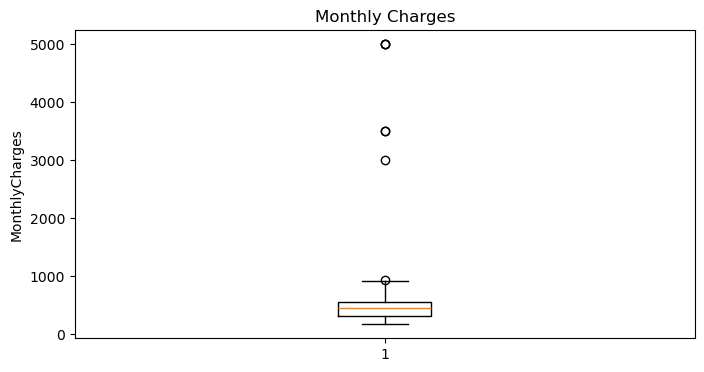

In [87]:
# YOUR CODE HERE
q1, q3 = data["MonthlyCharges"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
outliers = data[~data["MonthlyCharges"].between(low, high)]
print(len(outliers))
plt.boxplot(data["MonthlyCharges"].dropna())
plt.title("Monthly Charges")
plt.ylabel("MonthlyCharges")
plt.show()

### ✏️ Question B7
Remove the outliers, recalculate `TotalCharges = MonthlyCharges × TenureMonths`, and print the final shape.

In [88]:
# YOUR CODE HERE
data = data[data["MonthlyCharges"].between(low, high)].copy()
data["TotalCharges"] = data["MonthlyCharges"] * data["TenureMonths"]
print("Final shape:", data.shape)

Final shape: (993, 16)


💡 **Business insight:** Summarise what you cleaned and why it matters before analysis.

> *Write your answer here (double-click to edit)*

---
## Part C: EDA, Answering the Manager's Questions 🔍
For each question: calculate the **churn rate per group** (`groupby(...)['Churn'].mean()`) and draw a chart.

### ✏️ Question C1
**Which contract type churns the most?** Show the churn rate by `Contract` as a bar chart.

Contract
Month-to-month    0.512241
One year          0.183824
Two year          0.136842
Name: Churn, dtype: float64


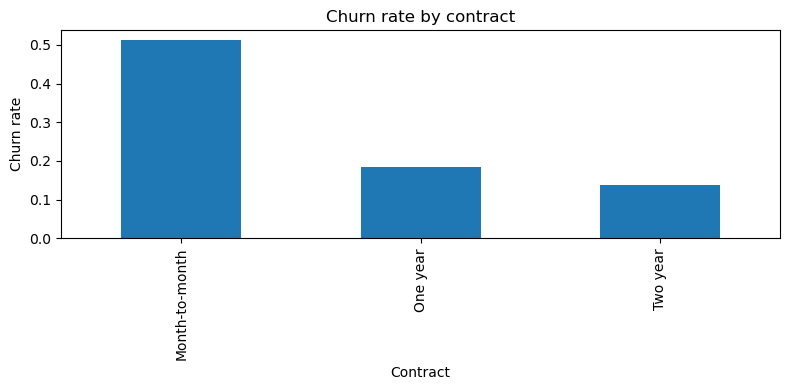

In [89]:
# YOUR CODE HERE
rate = data.groupby("Contract")["Churn"].mean().sort_values(ascending=False)
print(rate)
rate.plot(kind="bar", ylabel="Churn rate", title="Churn rate by contract")
plt.tight_layout(); plt.show()

### ✏️ Question C2
**Do plan and payment method matter?** Make side-by-side bar charts of the churn rate by `Plan` and by `PaymentMethod`.

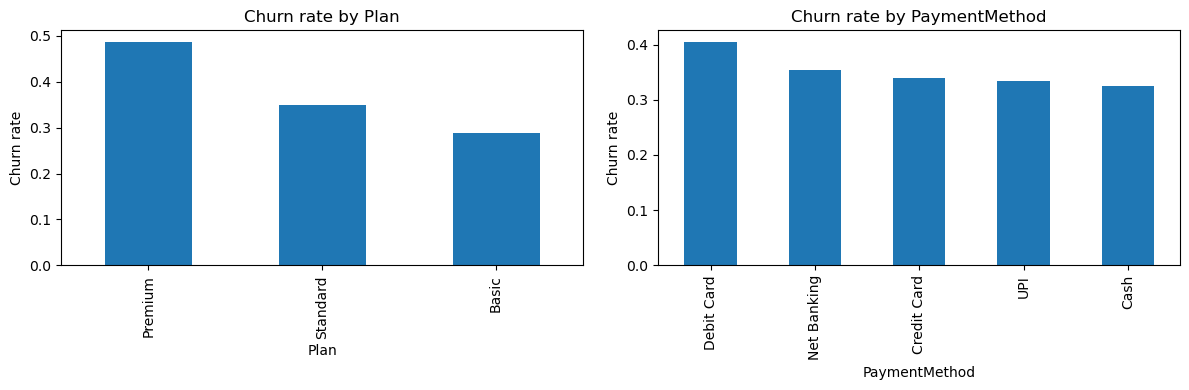

In [90]:
# YOUR CODE HERE
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, col in zip(ax, ["Plan", "PaymentMethod"]):
    data.groupby(col)["Churn"].mean().sort_values(ascending=False).plot(kind="bar", ax=a, title=f"Churn rate by {col}", ylabel="Churn rate")
plt.tight_layout(); plt.show()

### ✏️ Question C3
**Do unhappy customers call support more?** Compare the average `SupportCalls`, `SatisfactionScore`, `TenureMonths` and `MonthlyCharges` for churned vs stayed customers.

In [91]:
# YOUR CODE HERE
data.groupby("Churn")[["SupportCalls", "SatisfactionScore", "TenureMonths", "MonthlyCharges"]].mean().rename(index={0:"Stayed",1:"Churned"})

,SupportCalls,SatisfactionScore,TenureMonths,MonthlyCharges
Churn,,,,
Stayed,1.282171,3.373643,41.150388,446.168016
Churned,1.853448,2.586207,27.801724,510.642701


### ✏️ Question C4
Plot the **churn rate for each number of support calls**. What pattern do you see?

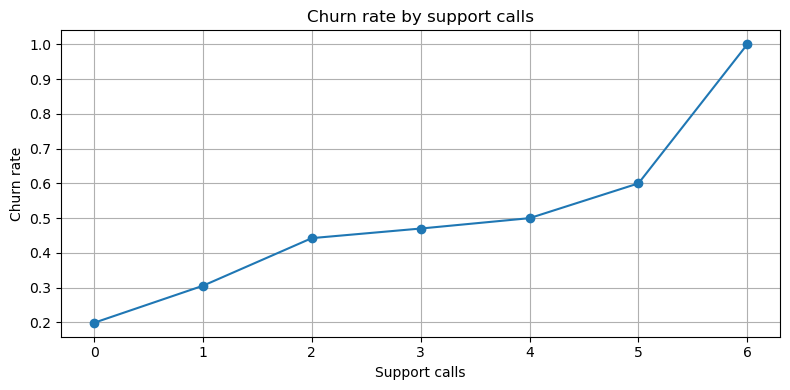

SupportCalls
0    0.199115
1    0.305638
2    0.442553
3    0.470149
4    0.500000
5    0.600000
6    1.000000
Name: Churn, dtype: float64

In [92]:
# YOUR CODE HERE
rate = data.groupby("SupportCalls")["Churn"].mean()
rate.plot(marker="o", title="Churn rate by support calls", xlabel="Support calls", ylabel="Churn rate")
plt.grid(True); plt.tight_layout(); plt.show()
rate

### ✏️ Question C5
**Does loyalty (tenure) matter?** Plot overlapping histograms of `TenureMonths` for churned and stayed customers.

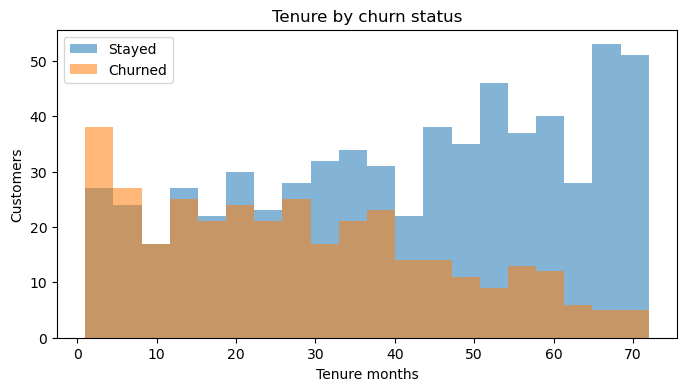

In [93]:
# YOUR CODE HERE
for label, value in [("Stayed", 0), ("Churned", 1)]:
    plt.hist(data.loc[data["Churn"] == value, "TenureMonths"], bins=20, alpha=.55, label=label)
plt.title("Tenure by churn status"); plt.xlabel("Tenure months"); plt.ylabel("Customers"); plt.legend(); plt.show()

### ✏️ Question C6
**Satisfaction vs churn:** show the churn rate for each `SatisfactionScore` (1–5).

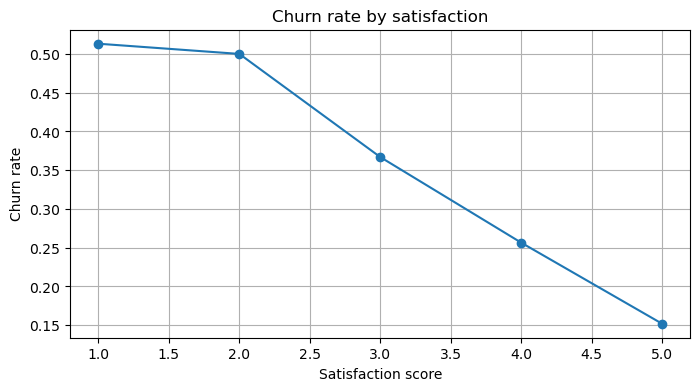

In [94]:
# YOUR CODE HERE
data.groupby("SatisfactionScore")["Churn"].mean().plot(marker="o", title="Churn rate by satisfaction", xlabel="Satisfaction score", ylabel="Churn rate")
plt.grid(True); plt.show()

### ✏️ Question C7
**Which city loses the most customers?** Show the number of customers, the number who churned, and the churn rate per city, sorted by churn rate.

In [95]:
# YOUR CODE HERE
city = data.groupby("City").agg(customers=("Churn","size"), churned=("Churn","sum"), churn_rate=("Churn","mean")).sort_values("churn_rate", ascending=False)
city

,customers,churned,churn_rate
City,,,
Bengaluru,145,61,0.420690
Chennai,92,34,0.369565
Kollam,99,36,0.363636
Kochi,274,99,0.361314
Kozhikode,128,45,0.351562
Thrissur,112,33,0.294643
Thiruvananthapuram,143,40,0.279720


### ✏️ Question C8
Make a **correlation heatmap** of the numeric columns. Which feature is most strongly linked with `Churn`?

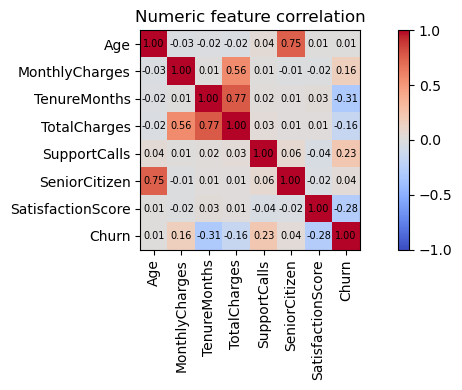

TenureMonths        -0.306017
SatisfactionScore   -0.278772
SupportCalls         0.225407
MonthlyCharges       0.158921
TotalCharges        -0.155209
SeniorCitizen        0.037126
Age                  0.005644
Name: Churn, dtype: float64

In [96]:
# YOUR CODE HERE
corr = data.select_dtypes(include="number").corr()
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(); plt.xticks(range(len(corr)), corr.columns, rotation=90); plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Numeric feature correlation"); plt.tight_layout(); plt.show()
corr["Churn"].drop("Churn").sort_values(key=abs, ascending=False)

💡 **Business insight:** Write the top 3 reasons customers churn, based on your EDA.

> *Write your answer here (double-click to edit)*

---
## Part C2: Visualising with Matplotlib 📊
Pandas' `.plot()` is a shortcut. **Matplotlib** gives you full control, and it's what you'll use for reports and presentations.

**Cheat sheet**
| Chart | Function | Use it for |
|---|---|---|
| Bar | `plt.bar(x, height)` / `plt.barh` | Comparing categories |
| Histogram | `plt.hist(values, bins=)` | Distribution of one number |
| Box plot | `plt.boxplot([group1, group2])` | Spread and outliers by group |
| Scatter | `plt.scatter(x, y, c=)` | Relationship between two numbers |
| Line | `plt.plot(x, y, marker="o")` | Trends / ordered values |
| Pie | `plt.pie(sizes, labels=, autopct=)` | Parts of a whole |

**Every chart:** `plt.figure(figsize=)` → plot → `plt.title` / `plt.xlabel` / `plt.ylabel` → `plt.legend()` / `plt.grid()` → `plt.show()` (or `plt.savefig("file.png")`).

### ✏️ Question V1
**Figure anatomy:** use `plt.bar` to draw the number of customers who **stayed vs churned**. Add a title, axis labels, a grid on the y-axis, and give the bars different colours.

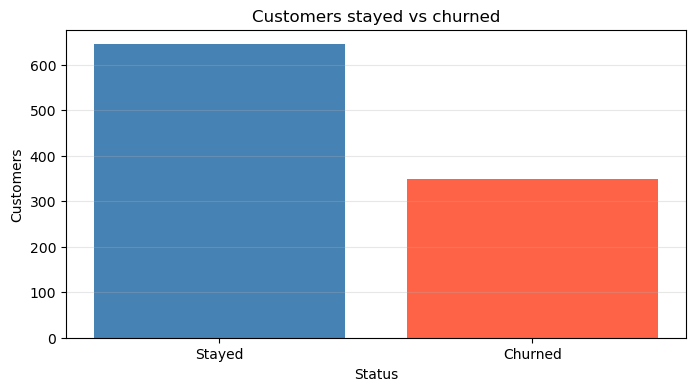

In [106]:
# YOUR CODE HERE
counts = data["Churn"].value_counts().reindex([0,1], fill_value=0)
plt.bar(["Stayed", "Churned"], counts.values, color=["steelblue", "tomato"])
plt.title("Customers stayed vs churned"); plt.xlabel("Status")
plt.ylabel("Customers")
plt.grid(axis="y", alpha=.3)
plt.show()

### ✏️ Question V2
**Bar chart with value labels:** plot the churn rate (%) by `Contract` and write each percentage on top of its bar.

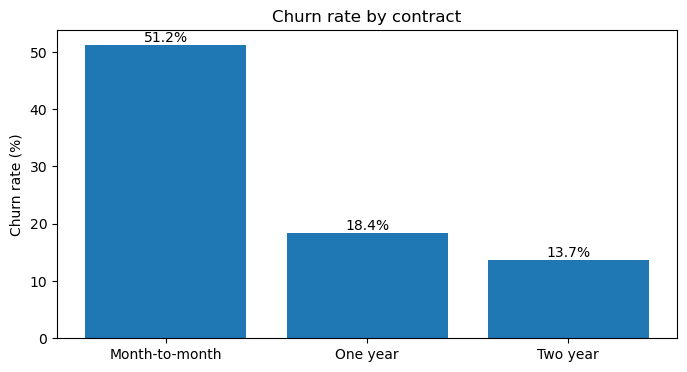

In [105]:
# YOUR CODE HERE
rate = data.groupby("Contract")["Churn"].mean()*100
bars = plt.bar(rate.index, rate.values)
plt.bar_label(bars, fmt="%.1f%%")
plt.title("Churn rate by contract")
plt.ylabel("Churn rate (%)")
plt.show()

### ✏️ Question V3
**Grouped bar chart:** for each `Plan`, show the number of customers who stayed and who churned as two bars side by side.

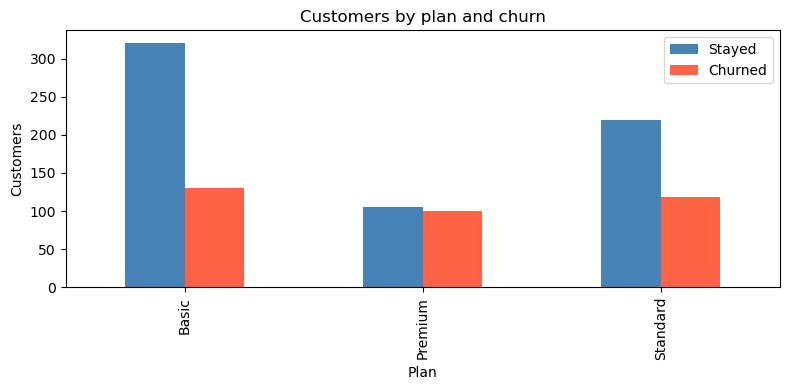

In [104]:
# YOUR CODE HERE
tab = data.groupby(["Plan", "Churn"]).size().unstack(fill_value=0).reindex(columns=[0,1], fill_value=0)
tab.plot(kind="bar", color=["steelblue", "tomato"], title="Customers by plan and churn")
plt.ylabel("Customers")
plt.legend(["Stayed", "Churned"])
plt.tight_layout()
plt.show()

### ✏️ Question V4
**Histogram:** draw overlapping histograms of `TenureMonths` for stayed and churned customers (use `alpha` and a legend).

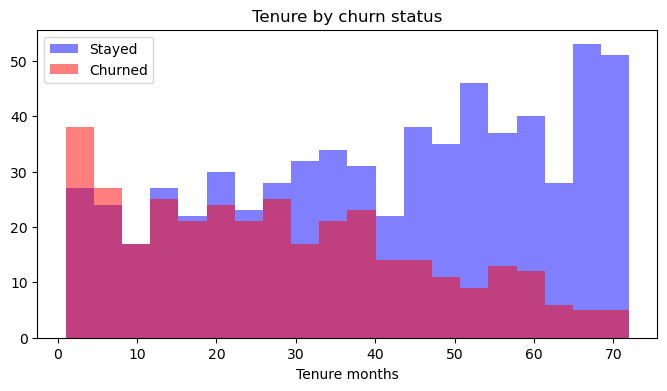

In [103]:
# YOUR CODE HERE
for label, value, color in [("Stayed",0,"blue"),("Churned",1,"red")]:
    plt.hist(data.loc[data["Churn"]==value,"TenureMonths"], bins=20, alpha=.5, color=color, label=label)
plt.title("Tenure by churn status")
plt.xlabel("Tenure months")
plt.legend()
plt.show()

### ✏️ Question V5
**Box plot:** compare `MonthlyCharges` across the three plans with `plt.boxplot`.

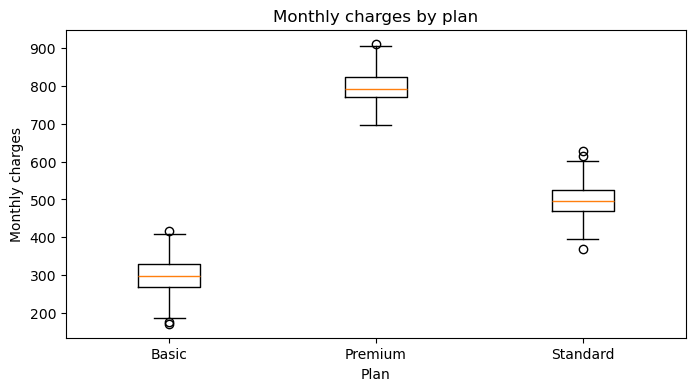

In [107]:
# YOUR CODE HERE
plans = sorted(data["Plan"].dropna().unique())
plt.boxplot([data.loc[data["Plan"]==p,"MonthlyCharges"].dropna() for p in plans], tick_labels=plans)
plt.title("Monthly charges by plan")
plt.xlabel("Plan")
plt.ylabel("Monthly charges")
plt.show()

### ✏️ Question V6
**Scatter plot:** plot `TenureMonths` (x) vs `MonthlyCharges` (y), red for churned and blue for stayed. Where do the churners cluster?

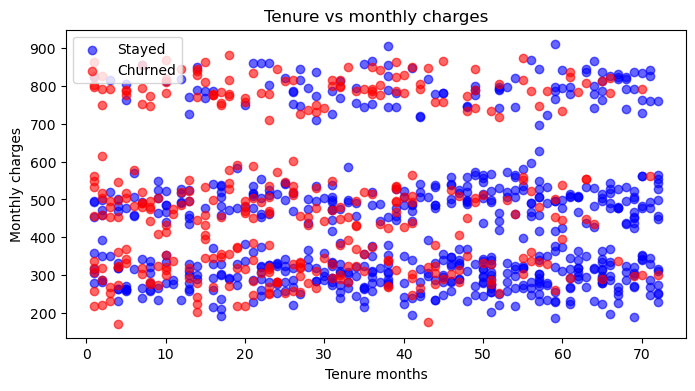

In [108]:
# YOUR CODE HERE
plt.scatter(data.loc[data["Churn"]==0,"TenureMonths"], data.loc[data["Churn"]==0,"MonthlyCharges"], c="blue", label="Stayed", alpha=.6)
plt.scatter(data.loc[data["Churn"]==1,"TenureMonths"], data.loc[data["Churn"]==1,"MonthlyCharges"], c="red", label="Churned", alpha=.6)
plt.xlabel("Tenure months")
plt.ylabel("Monthly charges")
plt.title("Tenure vs monthly charges")
plt.legend()
plt.show()

### ✏️ Question V7
**Pie + line in one figure:** using `plt.subplots(1, 2)`, draw (left) a pie of the churn split with percentages and (right) a line chart of churn rate by `SatisfactionScore`.

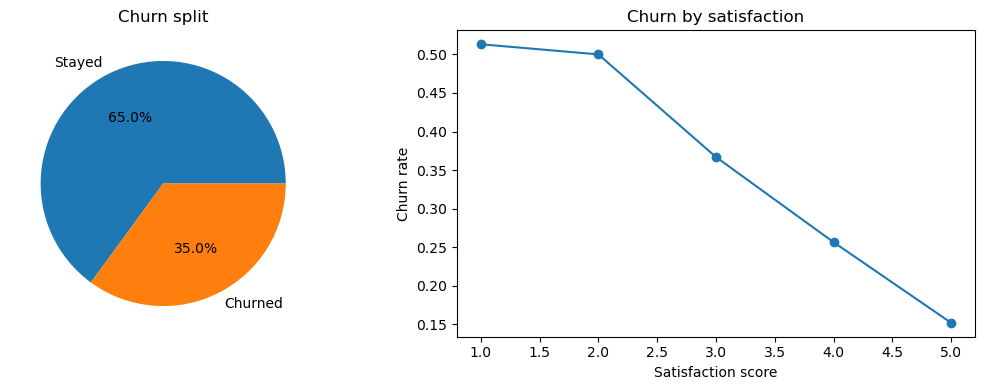

In [109]:
# YOUR CODE HERE
fig, (ax1, ax2) = plt.subplots(1,2,figsize=(11,4))
split = data["Churn"].value_counts().reindex([0,1],fill_value=0)
ax1.pie(split.values, labels=["Stayed","Churned"], autopct="%1.1f%%")
ax1.set_title("Churn split")
sr = data.groupby("SatisfactionScore")["Churn"].mean()
ax2.plot(sr.index,sr.values,marker="o")
ax2.set_title("Churn by satisfaction")
ax2.set_xlabel("Satisfaction score")
ax2.set_ylabel("Churn rate")
plt.tight_layout()
plt.show()

### ✏️ Question V8
📊 **Manager dashboard:** build a 2×2 figure with `plt.subplots(2, 2)` showing (1) churn rate by contract, (2) churn rate by support calls, (3) tenure histograms for churned vs stayed, (4) churn rate by payment method. Give it an overall title with `fig.suptitle` and save it as `churn_dashboard.png`.

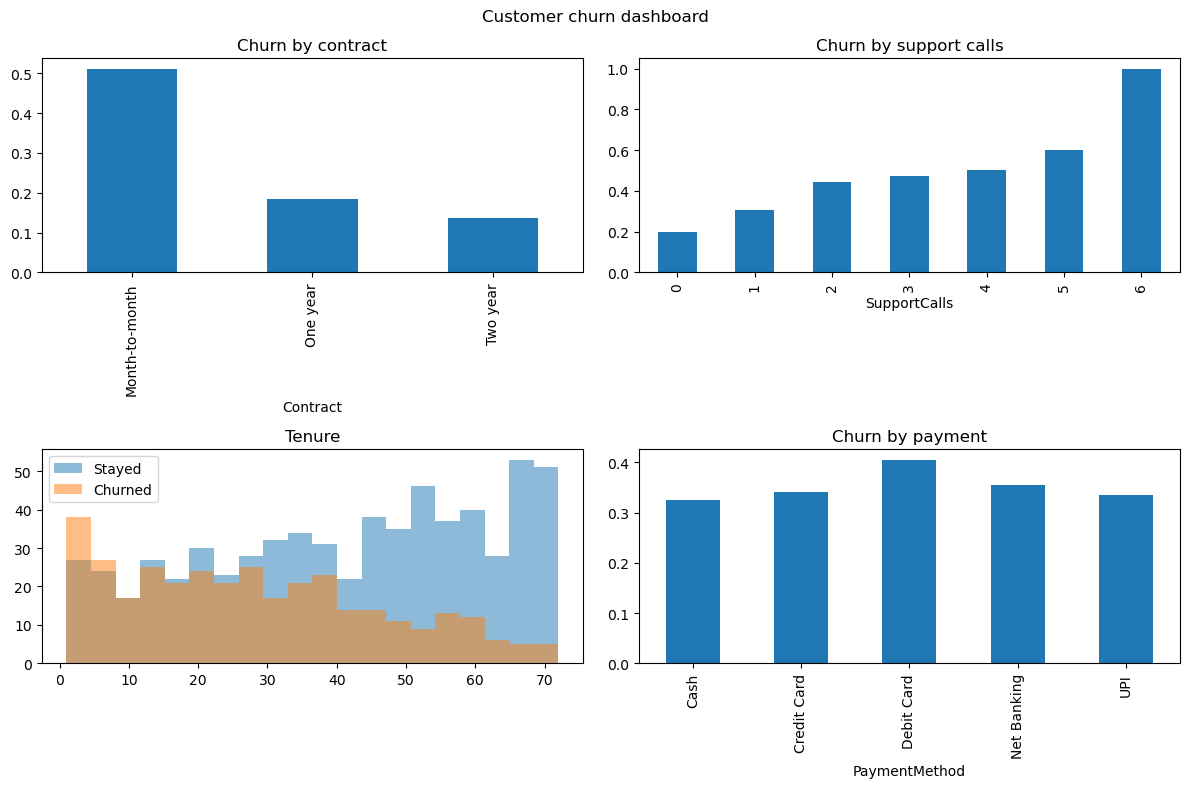

In [110]:
# YOUR CODE HERE
fig, ax = plt.subplots(2,2,figsize=(12,8))
data.groupby("Contract")["Churn"].mean().plot(kind="bar",ax=ax[0,0],title="Churn by contract")
data.groupby("SupportCalls")["Churn"].mean().plot(kind="bar",ax=ax[0,1],title="Churn by support calls")
for v,l in [(0,"Stayed"),(1,"Churned")]: ax[1,0].hist(data.loc[data["Churn"]==v,"TenureMonths"],bins=20,alpha=.5,label=l)
ax[1,0].set_title("Tenure"); ax[1,0].legend()
data.groupby("PaymentMethod")["Churn"].mean().plot(kind="bar",ax=ax[1,1],title="Churn by payment")
fig.suptitle("Customer churn dashboard")
plt.tight_layout()
plt.savefig("churn_dashboard.png",dpi=150)
plt.show()

💡 **Business insight:** Which chart would you put on the first slide for your manager, and why?

> *Write your answer here (double-click to edit)*

---
## Part D: Prepare the Data for a Model 🛠️
A model needs **numbers only**, a clear **target**, and separate **train** and **test** data.

### ✏️ Question D1
Create `X` from the features `TenureMonths`, `MonthlyCharges`, `SupportCalls`, `SatisfactionScore`, `Age`, `Contract`, `Plan`, `PaymentMethod`, and set `y = data['Churn']`.

In [111]:
# YOUR CODE HERE
features = ["TenureMonths","MonthlyCharges","SupportCalls","SatisfactionScore","Age","Contract","Plan","PaymentMethod"]
X = data[features].copy()
y = data["Churn"]

### ✏️ Question D2
Models can't read text. **One-hot encode** `Contract`, `Plan` and `PaymentMethod` with `pd.get_dummies(..., drop_first=True, dtype=int)`.

In [112]:
# YOUR CODE HERE
X = pd.get_dummies(X, columns=["Contract","Plan","PaymentMethod"], drop_first=True, dtype=int)

### ✏️ Question D3
Split the data 80/20 into train and test sets with `train_test_split` (`random_state=42`, `stratify=y`).

### ✏️ Question D4
**Scale** the features with `StandardScaler`: `fit_transform` on the training set, `transform` on the test set.

In [ ]:
# YOUR CODE HERE


### ✏️ Question D5
Check that the churn ratio is similar in `y_train` and `y_test`.

In [115]:
# YOUR CODE HERE


---
## Part E: Logistic Regression 🤖
Logistic regression outputs a **probability of churn** between 0 and 1. If it's ≥ 0.5, we predict **churn**.

### ✏️ Question E1
Create a `LogisticRegression()` model and fit it on the scaled training data.

In [ ]:
# YOUR CODE HERE


### ✏️ Question E2
Predict on the test set. Show a table of the first 10 rows with **Actual**, **Predicted** and **P(churn)**.

In [ ]:
# YOUR CODE HERE


### ✏️ Question E3
Print the **accuracy** and the **classification report**, and plot the **confusion matrix**.

In [ ]:
# YOUR CODE HERE


### ✏️ Question E3b
**Confusion matrix in plain matplotlib:** draw it yourself with `plt.imshow` and write each count in its cell.

In [ ]:
# YOUR CODE HERE


### ✏️ Question E4
Show the model's **coefficients** as a sorted horizontal bar chart. Which features push churn up, and which pull it down?

In [ ]:
# YOUR CODE HERE


### ✏️ Question E5
🎯 **Predict for a new customer:** 3 months tenure, ₹550 per month, 4 support calls, satisfaction 2, age 30, month-to-month contract, Standard plan, pays by UPI. What is their churn probability?

In [ ]:
# YOUR CODE HERE


💡 **Business insight:** Is this model useful to the manager? What does it get right, and what does it miss?

> *Write your answer here (double-click to edit)*

---
## Part F: Recommendations & Challenges 🚀

### ✏️ Question F1
Write **3 recommendations** for the manager as a markdown cell or `print` statements, based on your analysis.

In [ ]:
# YOUR CODE HERE


### ⭐ Challenge questions (optional)

### ✏️ Question F2
**Threshold tuning:** predict churn when P(churn) ≥ **0.35** instead of 0.5. How do recall and precision for churners change?

In [ ]:
# YOUR CODE HERE


### ✏️ Question F3
**Remove a feature:** retrain without the `Contract` columns. How much does accuracy drop? What does that tell you?

In [ ]:
# YOUR CODE HERE


### ✏️ Question F4
**Try another model:** fit a `DecisionTreeClassifier(max_depth=4, random_state=42)` and compare its accuracy.

In [ ]:
# YOUR CODE HERE


---
## 🎉 Well done!
You just completed a real data-analysis workflow: **load → clean → explore → prepare → model → recommend**. This is what data analysts and data scientists do every day.

**Next ideas:** try this workflow on a dataset you care about (cricket stats, Kerala rainfall, movie ratings from Kaggle), or learn more models (random forests, XGBoost).